### Classification Model for O-Scope Data

**kshape Classification**: We developed a simple classification model to distinguish between different EMF strengths during electrode actuation. Despite shielding from the ITO top plate, significant EMF leakage from the connecting wires provides a reliable basis for spatial localization. The primary RL model is built for an OMF platform (EMF on top of the electrode grid itself) and does not follow this scheme. Instead, this approach highlights how EMF can be detected on closed platforms, offering a path for localization in future closed-form DMFB research.

In [3]:
from tslearn.clustering import KShape
import os
import csv 
import re
import numpy as np
from matplotlib.pyplot import imread
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from scipy.spatial import Delaunay
from scipy.interpolate import LinearNDInterpolator

In [ ]:
base_path = "/Users/[]/Desktop/research/Droplet_Tracker_Modularized/official_repo/O_Scope_Data/TopPlateDroplet"
electrode_labels = [1,  2,  3,  4,  6,  7,  8,  9, 10, 11, 12, 13, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 28, 29, 30, 31, 32, 33, 34, 35, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 50, 51, 52, 53, 54, 55, 56, 57, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 72, 73, 74, 75, 76, 77, 78, 79, 81, 82, 83, 84]
waveform_data = {}

for n in range(1, 11):  # regions 1 to 10
    for k in electrode_labels:  # electrodes 1 to 84
        filename = base_path + f"/region {n}/tds7104_TopPlateDroplet_region{n}_{k}.csv"

        metadata = {}
        adc = []

        with open(filename, "r") as f:
            reader = csv.reader(f)

            data_section = False
            for row in reader:
                if not row:
                    continue

                # Read metadata
                if row[0] == "# Scope metadata":
                    continue

                if row[0] == "# Waveform data":
                    data_section = True
                    continue

                if not data_section:
                    metadata[row[0]] = row[1]
                else:
                    if row[0] == "PointIndex":
                        continue
                    adc.append(float(row[1]))

        adc = np.array(adc)

        # Extract scaling parameters
        YMULT = float(metadata["YMULT"])
        YOFF  = float(metadata["YOFF"])
        YZERO = float(metadata["YZERO"])

        XINCR = float(metadata["XINCR"])
        XZERO = float(metadata["XZERO"])

        # Apply Tektronix scaling
        voltage = (adc - YOFF) * YMULT + YZERO
        time = np.arange(len(voltage)) * XINCR + XZERO

        # Save processed waveform
        label = f"{n}_{k}"
        waveform_data[label] = time, voltage 


**normalize and align all waveforms**

In [5]:
normalized_waveform_data = {}

for label, (time, voltage) in waveform_data.items():
    scale = np.max(np.abs(voltage))
    if scale == 0:
        continue

    norm_voltage = voltage / scale
    normalized_waveform_data[label] = (time, norm_voltage)

In [6]:
period_us = 1.0        # period 
total_us = 3.0         # capture 3 periods for alignment 
fs = len(time) / 4.0   # samples per microsecond 

samples_per_period = int(period_us * fs)
samples_total = int(total_us * fs)

N_points = 1000  # downsample to make k-shape faster 
normalized_aligned_waveforms = {}

for label, (time, voltage) in normalized_waveform_data.items():
    first_period = voltage[:samples_per_period]
    peak_idx = np.argmax(first_period)
    
    shifted_voltage = np.roll(voltage, -peak_idx)

    sliced_voltage = shifted_voltage[:samples_total]

    x_axis = np.arange(len(sliced_voltage))
    
    normalized_aligned_waveforms[label] = (x_axis, sliced_voltage)
    
    # Downsample to N_points
    normalized_aligned_waveforms[label] = (np.linspace(0, len(sliced_voltage)-1, N_points), 
                                np.interp(np.linspace(0, len(sliced_voltage)-1, N_points), np.arange(len(sliced_voltage)), sliced_voltage))

**Plot normalized and aligned waveforms while specifying region** 

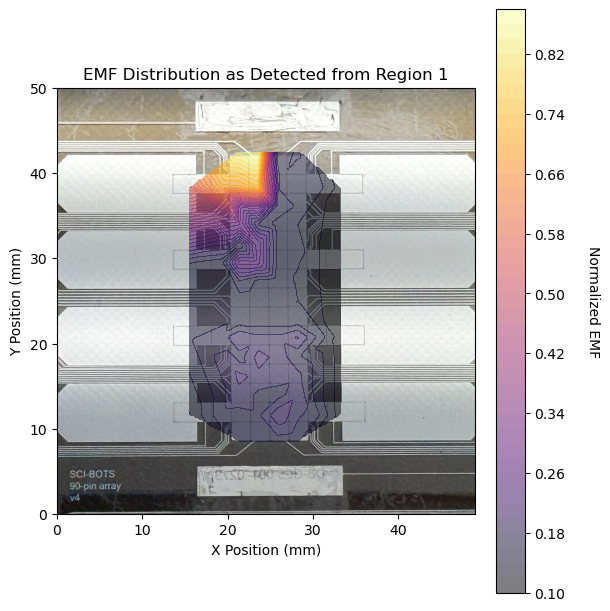

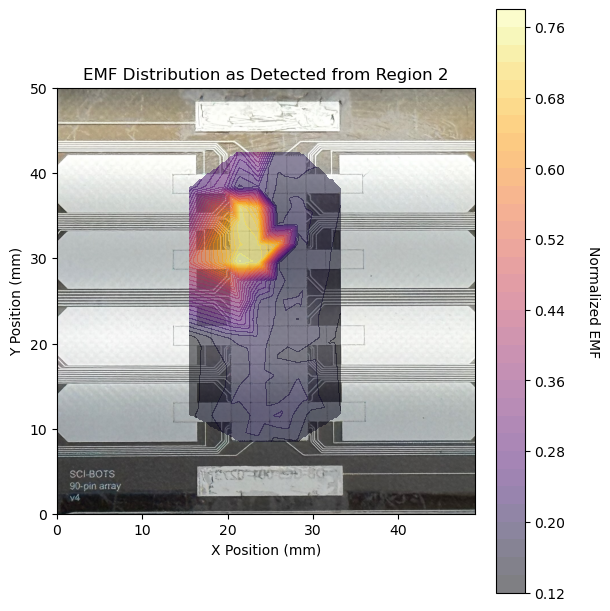

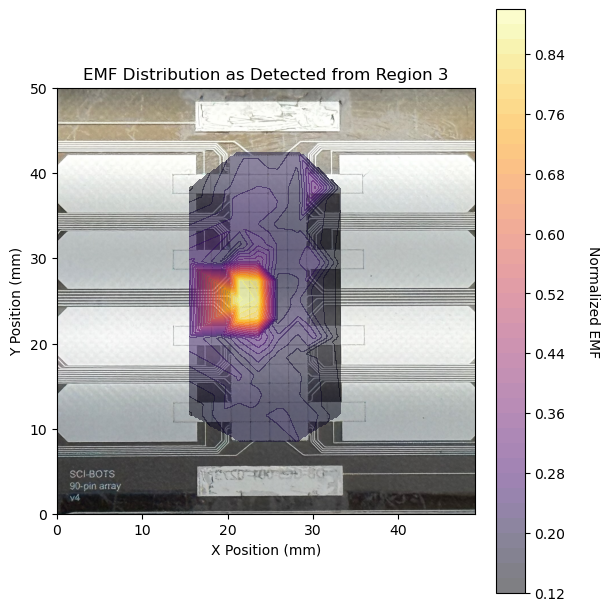

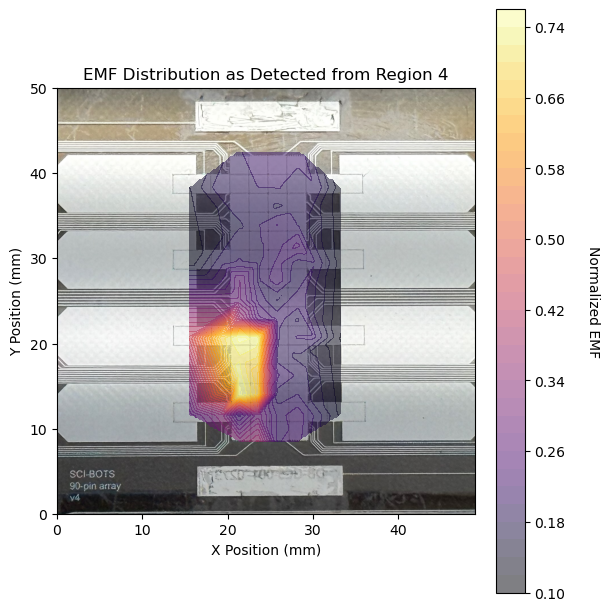

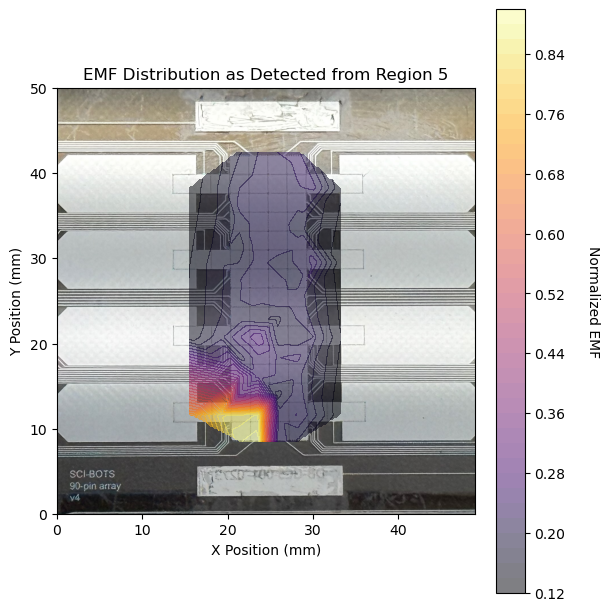

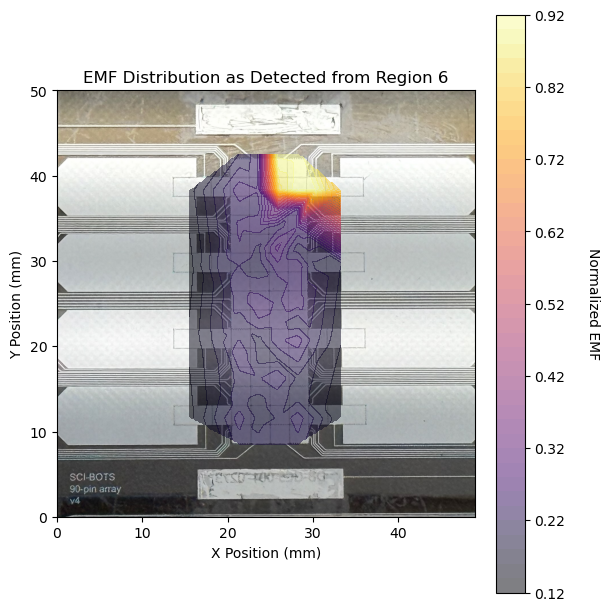

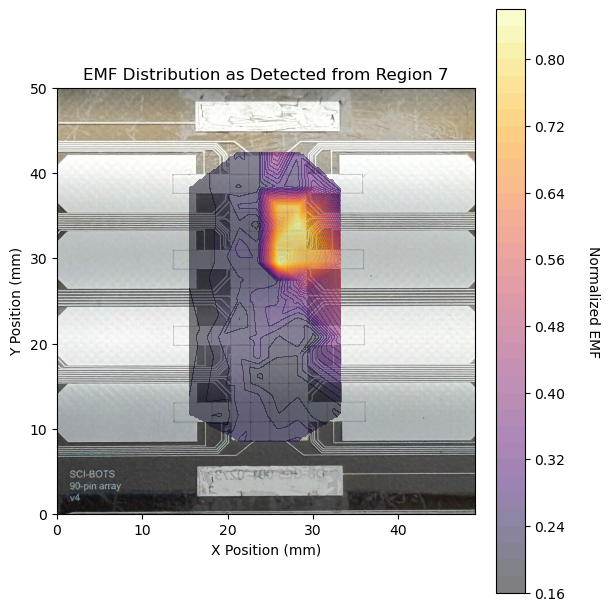

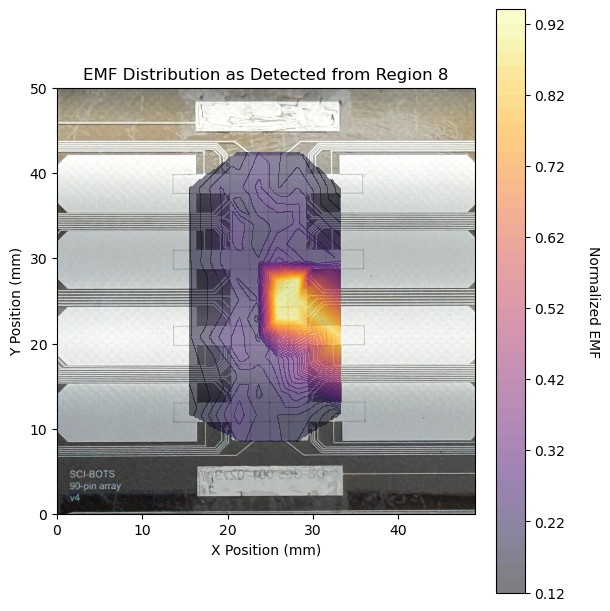

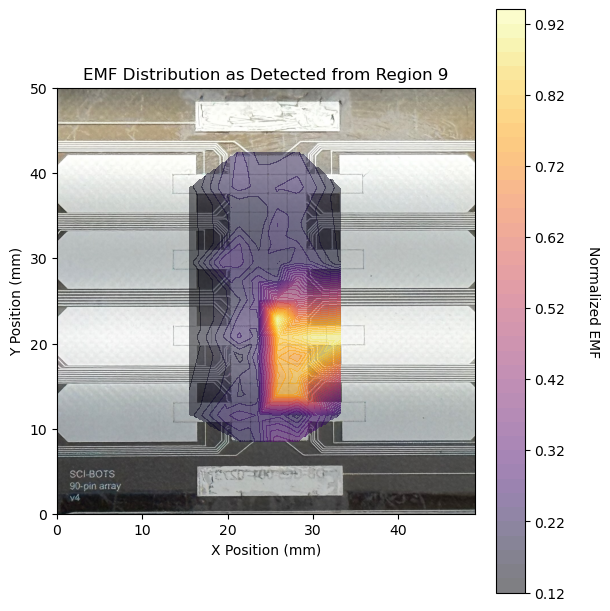

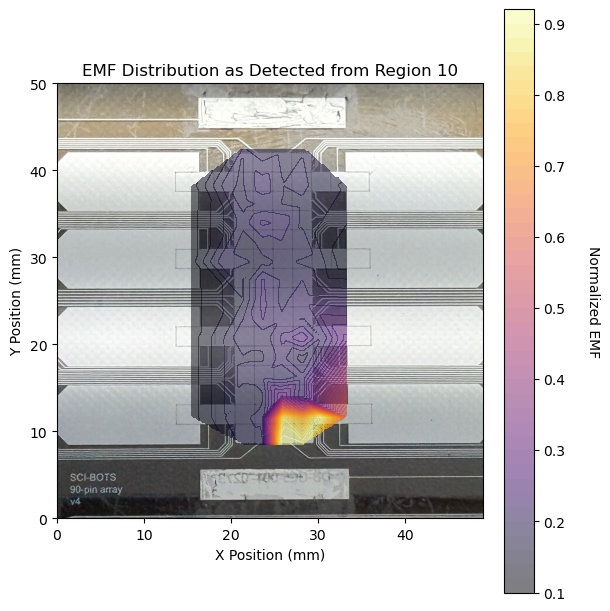

In [7]:

X_points = np.array([
    21.4, 23.6, 25.8, 28.25, 
    15.5, 19.2, 21.3, 23.6, 26, 28.2, 30.3, 33.3,
    21.4, 23.6, 25.8, 28.25, 
    21.4, 23.6, 25.8, 28.25,
    21.4, 23.6, 25.8, 28.25,
    15.5, 19.2, 21.3, 23.6, 26, 28.2, 30.3, 33.3,
    21.4, 23.6, 25.8, 28.25, 
    21.4, 23.6, 25.8, 28.25,
    21.4, 23.6, 25.8, 28.25,
    15.5, 19.2, 21.3, 23.6, 26, 28.2, 30.3, 33.3,
    21.4, 23.6, 25.8, 28.25, 
    21.4, 23.6, 25.8, 28.25,
    21.4, 23.6, 25.8, 28.25,
    15.5, 19.2, 21.3, 23.6, 26, 28.2, 30.3, 33.3,
    21.4, 23.6, 25.8, 28.25
])

Y_points = np.array([
    42.7, 42.7, 42.7, 42.7, 
    38.3, 38.3, 38.3, 38.3, 38.3, 38.3, 38.3, 38.3,
    36.1, 36.1, 36.1, 36.1, 
    34, 34, 34, 34, 
    31.6, 31.6, 31.6, 31.6,
    29.5, 29.5, 29.5, 29.5, 29.5, 29.5, 29.5, 29.5,
    27.4, 27.4, 27.4, 27.4, 
    25.1, 25.1, 25.1, 25.1,
    22.9, 22.9, 22.9, 22.9,
    20.75, 20.75, 20.75, 20.75, 20.75, 20.75, 20.75, 20.75,
    18.4, 18.4, 18.4, 18.4,
    16.25, 16.25, 16.25, 16.25,
    14, 14, 14, 14,
    11.6, 11.6, 11.6, 11.6, 11.6, 11.6, 11.6, 11.6,
    8.5, 8.5, 8.5, 8.5
])


x_grid = np.linspace(0, 49, 200)
y_grid = np.linspace(0, 50, 200)
X_grid, Y_grid = np.meshgrid(x_grid, y_grid)


DMFB = imread("../actual_chip.jpeg")
x0, y0 = 65, 1471
xEnd, yEnd = 1530, 0
DMFB_crop = DMFB[yEnd:y0, x0:xEnd]


for n in range(1, 11):

    waveforms = {
        k: v for k, v in normalized_aligned_waveforms.items()
        if k.startswith(f"{n}_")
    }

    waveforms = dict(sorted(
        waveforms.items(),
        key=lambda x: int(x[0].split("_")[1])
    ))

    Z_values = []
    for wf in waveforms.values():
        voltage = wf[1]
        neg_vals = voltage[voltage < 0]
        avg_neg = np.mean(neg_vals) if len(neg_vals) > 0 else 0.0
        Z_values.append(abs(avg_neg))

    Z_values = np.array(Z_values)
    assert len(Z_values) == len(X_points)

    interp = LinearNDInterpolator(
        list(zip(X_points, Y_points)),
        Z_values
    )

    Z_grid = interp(X_grid, Y_grid)

    plt.figure(figsize=(6, 6), constrained_layout=True)

    plt.imshow(
        DMFB_crop,
        extent=[0, 49, 50, 0],
        origin="lower"
    )

    contour = plt.contourf(
        X_grid,
        Y_grid,
        Z_grid,
        levels=40,
        cmap="inferno",
        alpha=0.5
    )

    plt.xlabel("X Position (mm)")
    plt.ylabel("Y Position (mm)")
    plt.xlim(0, 49)
    plt.ylim(0, 50)

    cbar = plt.colorbar(contour)
    cbar.set_label("Normalized EMF", rotation=270, labelpad=25)

    plt.title(f"EMF Distribution as Detected from Region {n}")

    plt.show()


In [8]:
X_train, X_test = [], []
labels_train, labels_test = [], []

X, labels = [], []
for label, (x, y) in normalized_aligned_waveforms.items():
    X.append(y)
    labels.append(label)

X = np.array(X)
labels = np.array(labels)

X_train, X_test, labels_train, labels_test = train_test_split(
    X, labels, test_size=0.2, random_state=42, shuffle=True
)

# tslearn requires 3D shape (samples, timepoints, 1)
X_train_ts = X_train[:, :, np.newaxis]
X_test_ts  = X_test[:, :, np.newaxis]

n_clusters = 4

# k-shape clustering
ks = KShape(n_clusters=n_clusters, random_state=42, n_init=10)
ks_labels_train = ks.fit_predict(X_train_ts)
ks_labels_test  = ks.predict(X_test_ts)




OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


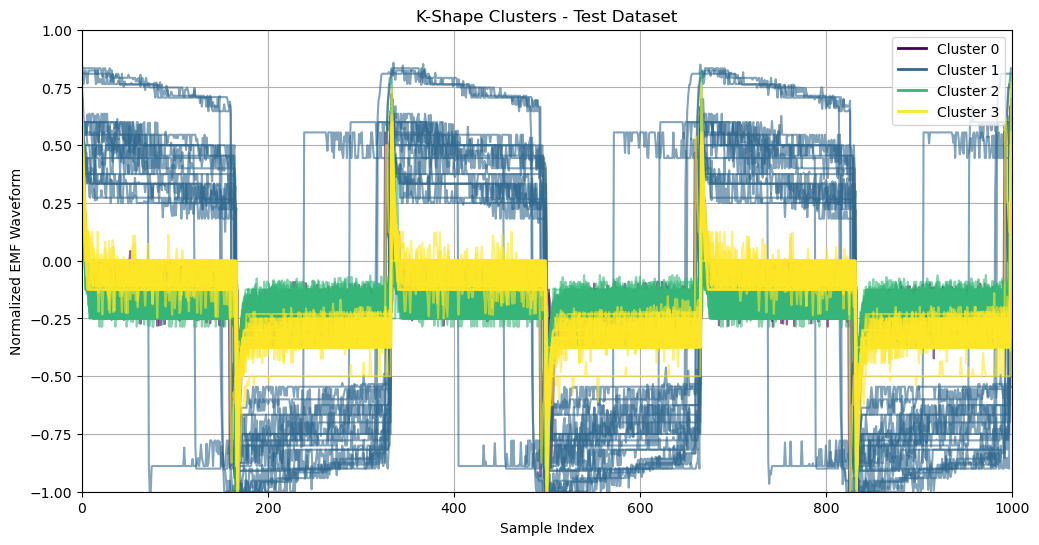

In [9]:

def plot_clusters(X, cluster_assignments, title="Cluster Visualization"):
    X = np.array(X)
    cluster_assignments = np.array(cluster_assignments)
    n_clusters = len(set(cluster_assignments))
    
    plt.figure(figsize=(12, 6))
    colors = plt.cm.viridis(np.linspace(0, 1, n_clusters))
    
    for cluster in range(n_clusters):
        cluster_indices = np.where(cluster_assignments == cluster)[0]
        for idx in cluster_indices:
            plt.plot(X[idx], color=colors[cluster], alpha=0.6)
    
    handles = [plt.Line2D([0], [0], color=colors[c], lw=2) for c in range(n_clusters)]
    labels = [f"Cluster {c}" for c in range(n_clusters)]
    plt.legend(handles, labels, loc='best')
    
    plt.title(title)
    plt.xlabel("Sample Index")
    plt.ylabel("Normalized EMF Waveform")
    plt.xlim(0, X.shape[1])
    plt.ylim(-1,1)
    plt.grid(True)
    plt.show()


plot_clusters(X_test, ks_labels_test, title="K-Shape Clusters - Test Dataset")


**Overlay cluster classification alongside Signal Distribution**

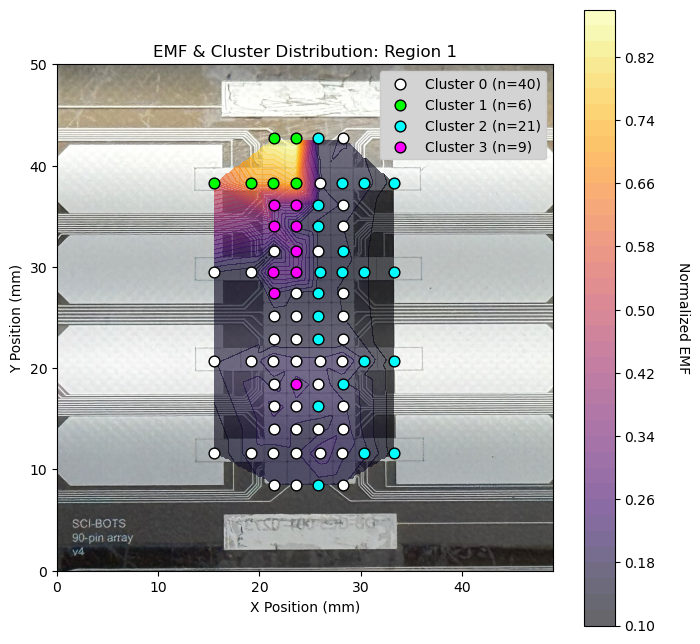

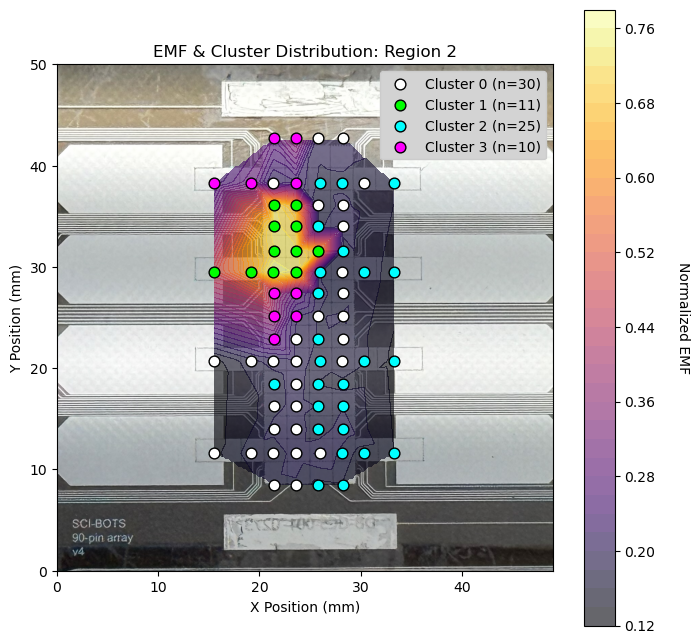

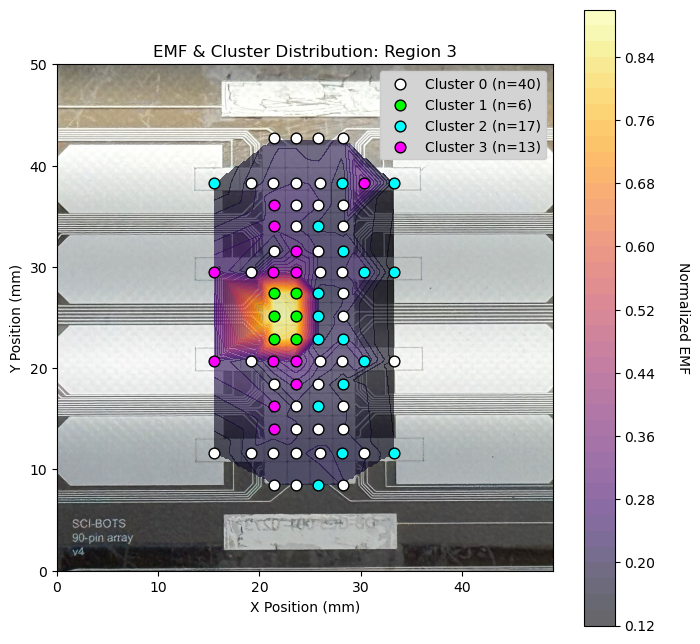

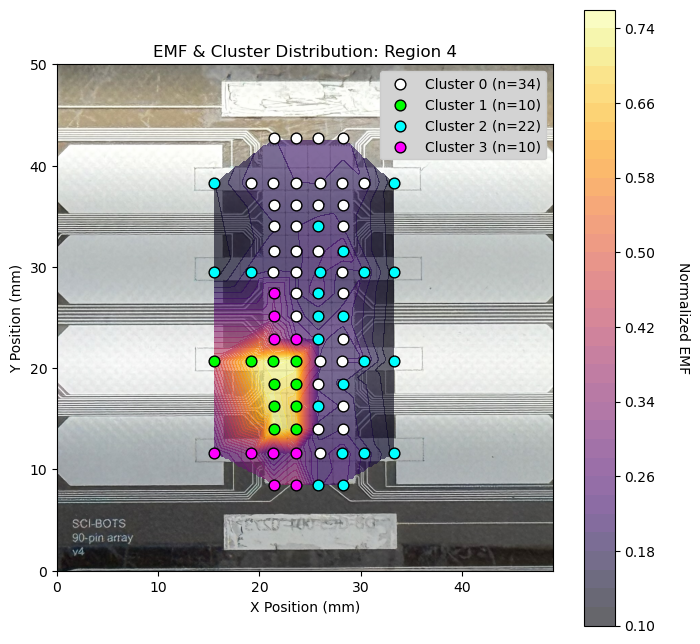

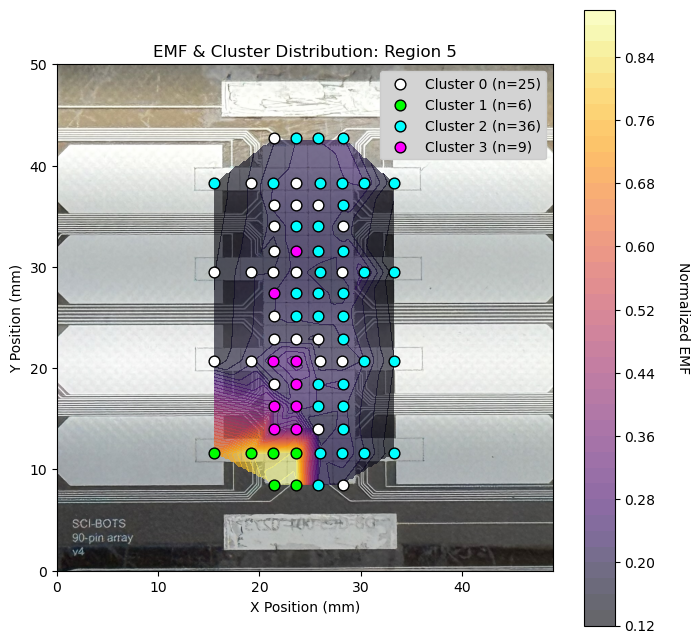

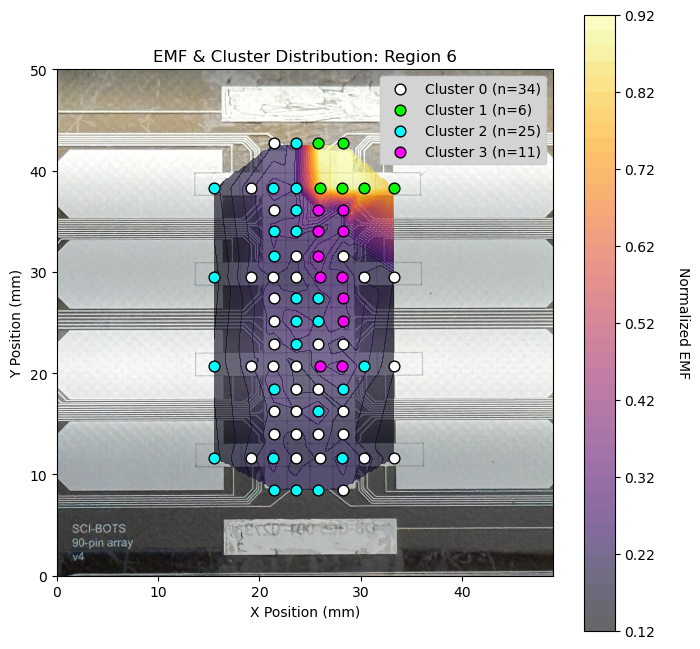

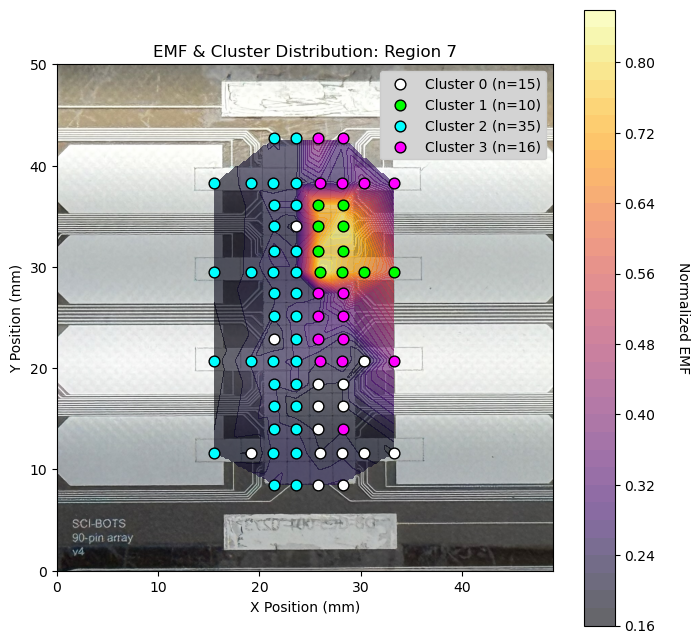

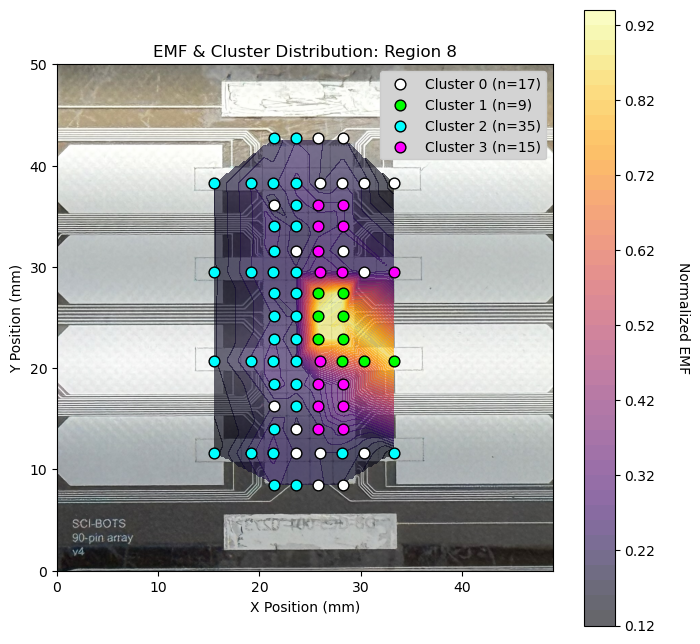

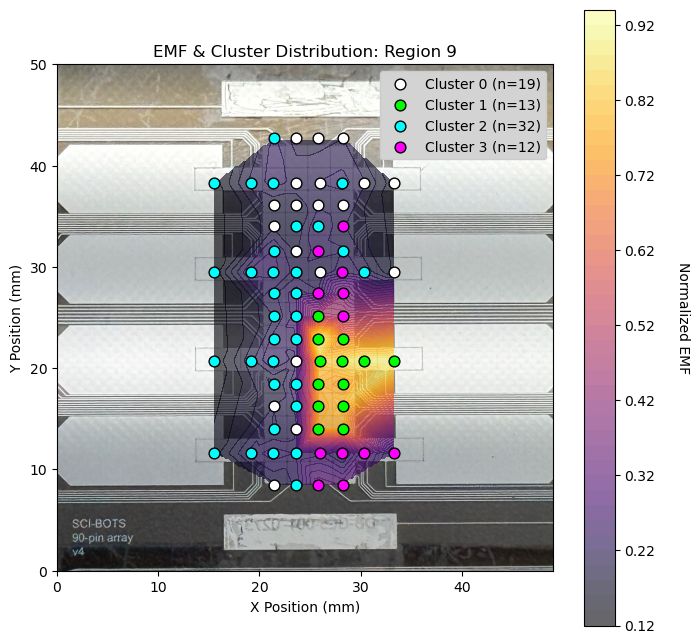

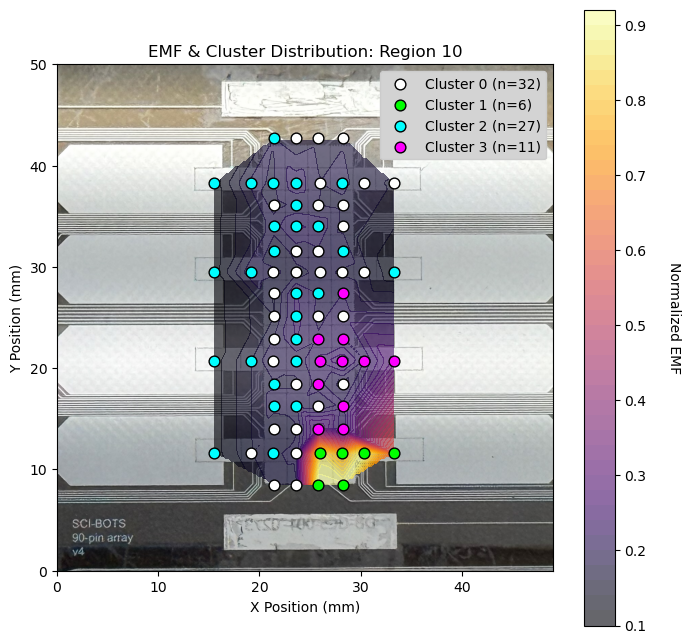

In [10]:
# colors 
contrast_colors = ['#FFFFFF', '#00FF00', '#00FFFF', '#FF00FF']

for n in range(1, 11):
    region_data = {k: v for k, v in normalized_aligned_waveforms.items() if k.startswith(f"{n}_")}
    sorted_keys = sorted(region_data.keys(), key=lambda x: int(x.split("_")[1]))
    
    Z_values = []
    region_cluster_ids = []

    for k in sorted_keys:
        waveform = region_data[k][1] 
        neg_vals = waveform[waveform < 0]
        Z_values.append(abs(np.mean(neg_vals)) if len(neg_vals) > 0 else 0.0)
        
        wf_3d = waveform.reshape(1, -1, 1)
        region_cluster_ids.append(ks.predict(wf_3d)[0])

    Z_values = np.array(Z_values)
    region_cluster_ids = np.array(region_cluster_ids)

    # background EMF 
    interp = LinearNDInterpolator(list(zip(X_points, Y_points)), Z_values)
    Z_grid = interp(X_grid, Y_grid)

    plt.figure(figsize=(8, 8))
    
    plt.imshow(DMFB_crop, extent=[0, 49, 0, 50], origin="upper")
    contour = plt.contourf(X_grid, Y_grid, Z_grid, levels=40, cmap="inferno", alpha=0.6, extent=[0, 49, 0, 50])
    cbar = plt.colorbar(contour)
    cbar.set_label("Normalized EMF", rotation=270, labelpad=25)

    # Plot cluster dots
    for c_id in range(n_clusters):
        mask = (region_cluster_ids == c_id)
        if np.any(mask):
            plt.scatter(X_points[mask], Y_points[mask], 
                        color=contrast_colors[c_id], 
                        label=f"Cluster {c_id} (n={np.sum(mask)})",
                        edgecolor='black', s=60, zorder=10)

    plt.xlabel("X Position (mm)")
    plt.ylabel("Y Position (mm)")
    plt.title(f"EMF & Cluster Distribution: Region {n}")
    plt.legend(loc='upper right', facecolor='lightgrey', framealpha=1)
    plt.ylim(0, 50) 
    plt.show()